In [12]:
import numpy as np
from sklearn.datasets import fetch_california_housing

In [13]:
def load_data() :
    data = fetch_california_housing()
    return data.data , data.target

In [14]:
def compute_fx(x,w,b) :
    return np.dot(x,w) + b


In [15]:
def z_score(x) :
    mu = x.mean(axis=0)
    std = x.std(axis=0)
    x_scaled = (x-mu)/std
    return x_scaled , mu , std

In [16]:
def cost_function_MSE(x,y,w,b) :
    m = x.shape[0]
    fx = compute_fx(x,w,b)
    error = (fx-y)**2
    cost = np.sum(error)/(2*m)
    return cost

In [17]:
def compute_gradient(x,y,w,b) :
    m = x.shape[0]
    fx = compute_fx(x,w,b)
    error = fx-y
    dj_dw = np.dot(x.T,error)/m
    dj_db = sum(error)/m
    return dj_dw , dj_db


In [18]:
def gradient_descent(x,y,w,b,alpha,iterations) :
    w_init = w.copy()
    b_init = b
    J_history = []

    for i in range(iterations):
        dj_dw , dj_db = compute_gradient(x,y,w_init,b_init)
        w_init = w_init - alpha * dj_dw
        b_init = b_init - alpha * dj_db
        J_history.append(cost_function_MSE(x,y,w_init,b_init))
        if i % 100 == 0:
            print(f"Iteration {i} cost : {J_history[-1]:.4f}")
    return w_init , b_init , J_history



In [19]:
if __name__ == "__main__" : 
    x,y = load_data()
    x_scaled,mean , std = z_score(x)
    # print("X shape:", x.shape, "y shape:", y.shape)
    # print("first row:", x[0])
    print(f"X Scaled : {x_scaled} , Mean : {mean} , STD : {std}")
    print('='*50)
    print(f"X Scaled with built in functions : \nMean : {x_scaled.mean(axis = 0)}\nSTD : {x_scaled.std(axis=0)}")

    w = np.zeros(8)
    b = 0
    print(cost_function_MSE(x_scaled, y, w, b))    # about 2.8
    dw, db = compute_gradient(x_scaled, y, w, b)
    print(dw.shape, db) 

X Scaled : [[ 2.34476576  0.98214266  0.62855945 ... -0.04959654  1.05254828
  -1.32783522]
 [ 2.33223796 -0.60701891  0.32704136 ... -0.09251223  1.04318455
  -1.32284391]
 [ 1.7826994   1.85618152  1.15562047 ... -0.02584253  1.03850269
  -1.33282653]
 ...
 [-1.14259331 -0.92485123 -0.09031802 ... -0.0717345   1.77823747
  -0.8237132 ]
 [-1.05458292 -0.84539315 -0.04021111 ... -0.09122515  1.77823747
  -0.87362627]
 [-0.78012947 -1.00430931 -0.07044252 ... -0.04368215  1.75014627
  -0.83369581]] , Mean : [ 3.87067100e+00  2.86394864e+01  5.42899974e+00  1.09667515e+00
  1.42547674e+03  3.07065516e+00  3.56318614e+01 -1.19569704e+02] , STD : [1.89977569e+00 1.25852527e+01 2.47411320e+00 4.73899376e-01
 1.13243469e+03 1.03857980e+01 2.13590065e+00 2.00348319e+00]
X Scaled with built in functions : 
Mean : [ 5.50808322e-17  4.40646658e-17  7.71131651e-17 -1.00522519e-16
 -1.10161664e-17  0.00000000e+00  2.24729795e-15 -8.60362599e-15]
STD : [1. 1. 1. 1. 1. 1. 1. 1.]
2.8052415994936264
(

In [20]:
    alpha = 0.1
    iterations = 5000
    w,b , J_history= gradient_descent(x_scaled,y,w,b,alpha,iterations)

Iteration 0 cost : 2.3315
Iteration 100 cost : 0.2762
Iteration 200 cost : 0.2654
Iteration 300 cost : 0.2630
Iteration 400 cost : 0.2624
Iteration 500 cost : 0.2622
Iteration 600 cost : 0.2622
Iteration 700 cost : 0.2622
Iteration 800 cost : 0.2622
Iteration 900 cost : 0.2622
Iteration 1000 cost : 0.2622
Iteration 1100 cost : 0.2622
Iteration 1200 cost : 0.2622
Iteration 1300 cost : 0.2622
Iteration 1400 cost : 0.2622
Iteration 1500 cost : 0.2622
Iteration 1600 cost : 0.2622
Iteration 1700 cost : 0.2622
Iteration 1800 cost : 0.2622
Iteration 1900 cost : 0.2622
Iteration 2000 cost : 0.2622
Iteration 2100 cost : 0.2622
Iteration 2200 cost : 0.2622
Iteration 2300 cost : 0.2622
Iteration 2400 cost : 0.2622
Iteration 2500 cost : 0.2622
Iteration 2600 cost : 0.2622
Iteration 2700 cost : 0.2622
Iteration 2800 cost : 0.2622
Iteration 2900 cost : 0.2622
Iteration 3000 cost : 0.2622
Iteration 3100 cost : 0.2622
Iteration 3200 cost : 0.2622
Iteration 3300 cost : 0.2622
Iteration 3400 cost : 0.26

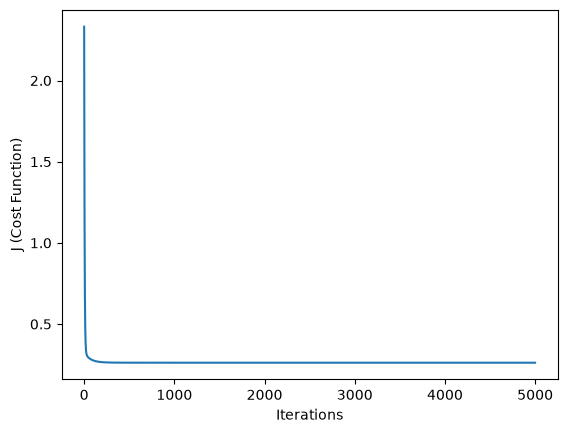

In [21]:
import matplotlib.pyplot as plt

plt.plot(J_history)
plt.xlabel("Iterations")
plt.ylabel("J (Cost Function)")
plt.show()

In [22]:
from sklearn.linear_model import LinearRegression
m= LinearRegression().fit(x_scaled,y)
print(w,b) #My w ,b
print(m.coef_,m.intercept_) #LR from Sklearn w ,b

[ 0.8296193   0.11875165 -0.26552688  0.30569623 -0.004503   -0.03932627
 -0.89988565 -0.870541  ] 2.068558169089141
[ 0.8296193   0.11875165 -0.26552688  0.30569623 -0.004503   -0.03932627
 -0.89988565 -0.870541  ] 2.068558169089142


*Used 5000 iterations for full convergence instead of 1000*

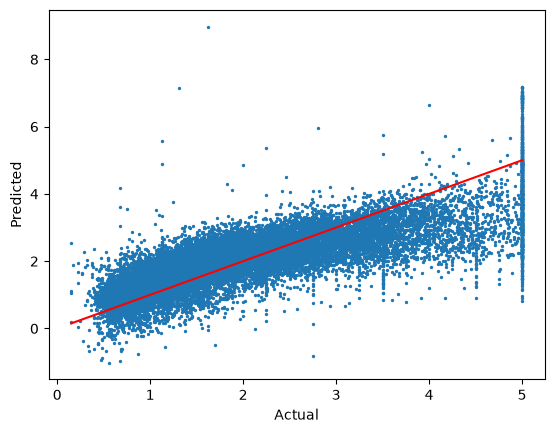

In [24]:
y_pred = compute_fx(x_scaled,w,b) 
plt.scatter(y,y_pred,s=2)
plt.plot([y.min(),y.max()],[y.min(),y.max()],'r')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()